# Final Assignment

In [24]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
sns.set(rc={'figure.figsize':(15, 9)})
sns.set(font_scale=1.5)

### Part 1

The `food_consumption.csv` dataset from the `data` folder contains data on the several countries' food consumption per food category and their respective CO2 emissions. Load it to a DataFrame named `food` and check its contents.

In [25]:
import pandas as pd

food = pd.read_csv('data/food_consumption.csv')
print(food.head())
print(food.info())

     country food_category  consumption  co2_emission
0  Argentina          pork        10.51         37.20
1  Argentina       poultry        38.66         41.53
2  Argentina          beef        55.48       1712.00
3  Argentina     lamb_goat         1.56         54.63
4  Argentina          fish         4.36          6.96
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1430 entries, 0 to 1429
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   country        1430 non-null   object 
 1   food_category  1430 non-null   object 
 2   consumption    1430 non-null   float64
 3   co2_emission   1430 non-null   float64
dtypes: float64(2), object(2)
memory usage: 44.8+ KB
None


1. Use the `.describe()` method on the `food` DataFrame to produce descriptive statistics about the `consumption` metric for each class in the `food_category` variable. **Which `food_category` has the highest median value of `food_consumption`?**

In [26]:
import pandas as pd

food = pd.read_csv('data/food_consumption.csv')

consumption_stats = food.groupby('food_category')['consumption'].describe()

print(consumption_stats)

highest_median_category = consumption_stats['50%'].idxmax()
print(f"Highest median category: {highest_median_category}")

               count        mean        std   min      25%      50%       75%  \
food_category                                                                   
beef           130.0   12.123385   9.654140  0.78   4.9975    8.285   17.9400   
dairy          130.0  125.774692  93.327721  3.04  45.7925  110.975  192.7150   
eggs           130.0    8.163769   5.032582  0.16   3.9450    8.420   12.3125   
fish           130.0   17.287077  19.013508  0.24   6.0250   13.950   21.8525   
lamb_goat      130.0    2.600154   3.665252  0.00   0.5600    1.325    3.1025   
nuts           130.0    4.137231   3.372817  0.18   1.8050    3.495    5.6100   
pork           130.0   16.123692  15.717646  0.00   2.0900   10.355   28.2275   
poultry        130.0   21.219231  14.571980  0.47  10.9100   19.855   29.7475   
rice           130.0   29.375154  37.324471  0.95   4.7200   11.875   43.4425   
soybeans       130.0    0.860538   2.083336  0.00   0.0100    0.075    0.6400   
wheat          130.0   71.54

2. In a single chart, plot one boxplot for each `food_category` (11 in total) using the variable `co2_emission` as the metric. **By looking at the chart, which `food_category` has the highest interquartile range (IQR)?**

IQR values sorted descending:
food_category
beef         399.3775
dairy        209.2725
pork          92.5200
lamb_goat     89.0375
rice          49.5500
fish          25.2700
poultry       20.2300
wheat         12.6450
eggs           7.6850
nuts           6.7350
soybeans       0.2900
Name: co2_emission, dtype: float64


<Figure size 1200x600 with 0 Axes>

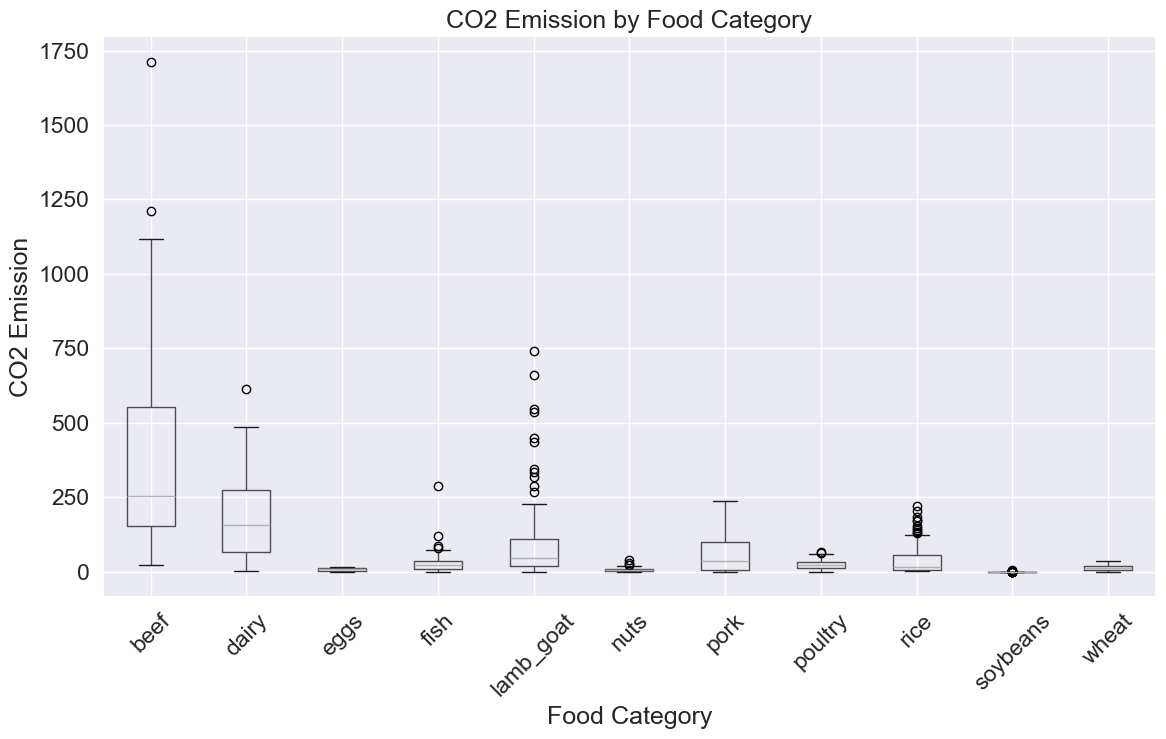

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

food = pd.read_csv('data/food_consumption.csv')

plt.figure(figsize=(12, 6))
food.boxplot(column='co2_emission', by='food_category', figsize=(12, 8), rot=45)
plt.title('CO2 Emission by Food Category')
plt.suptitle('') 
plt.ylabel('CO2 Emission')
plt.xlabel('Food Category')
plt.tight_layout()
plt.savefig('co2_boxplot.png')

q1 = food.groupby('food_category')['co2_emission'].quantile(0.25)
q3 = food.groupby('food_category')['co2_emission'].quantile(0.75)
iqr = q3 - q1
print("IQR values sorted descending:")
print(iqr.sort_values(ascending=False))

3. Looking at the chart from the previous question, which is the `food_category` with the highest median `co2_emission` value?

In [10]:
import pandas as pd

food = pd.read_csv('data/food_consumption.csv')

median_co2 = food.groupby('food_category')['co2_emission'].median().sort_values(ascending=False)

print(median_co2)

highest_median_category = median_co2.idxmax()
highest_median_value = median_co2.max()

print(f"\nFood category with the highest median co2_emission: {highest_median_category} ({highest_median_value})")

food_category
beef         255.655
dairy        158.075
lamb_goat     46.405
pork          36.650
fish          22.270
poultry       21.325
rice          15.200
wheat         13.240
eggs           7.735
nuts           6.185
soybeans       0.035
Name: co2_emission, dtype: float64

Food category with the highest median co2_emission: beef (255.655)


4. Consider the `consumption` of "poultry" and "fish" across all available `countries`; looking at the table from question 1, the average of poultry consumption (21.22) seems to be higher than that of fish consumption (17.29), but is this difference statistically significant? Create a permutation test in order to assess the null hypothesis that there is no difference between the two means. **Do you accept or reject the null hypothesis?** Explain why.

In [12]:
import pandas as pd
import numpy as np

food = pd.read_csv('data/food_consumption.csv')

poultry_data = food[food['food_category'] == 'poultry']['consumption']
fish_data = food[food['food_category'] == 'fish']['consumption']

observed_diff = np.mean(poultry_data) - np.mean(fish_data)

combined_data = np.concatenate((poultry_data, fish_data))

n_permutations = 10000
perm_diffs = np.empty(n_permutations)

np.random.seed(42)

for i in range(n_permutations):
    permuted_data = np.random.permutation(combined_data)
    perm_poultry = permuted_data[:len(poultry_data)]
    perm_fish = permuted_data[len(poultry_data):]
    perm_diffs[i] = np.mean(perm_poultry) - np.mean(perm_fish)

p_value = np.sum(np.abs(perm_diffs) >= np.abs(observed_diff)) / n_permutations

print(f"Observed Difference: {observed_diff:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Conclusion: Reject the null hypothesis.")
else:
    print("Conclusion: Fail to reject the null hypothesis.")

Observed Difference: 3.9322
P-value: 0.0597
Conclusion: Fail to reject the null hypothesis.


EXPLANATION
The p-value of 0.0597 indicates that if there were truly no difference between the mean consumption of poultry and fish, there is roughly a 6% chance of observing a difference as large as (or larger than) 3.93 purely by random chance. Since this probability is higher than the standard threshold of 0.05, we do not have sufficient statistical evidence to conclude that the difference in consumption between poultry and fish is significant. The difference we see could reasonably be due to sampling variability.

### Part 2

The `distributions.csv` dataset from the `data` folder contains data drawn from 6 probability distributions – one per column. Load it to a DataFrame named `distributions` and check its contents.

In [13]:
import pandas as pd

distributions = pd.read_csv('data/distributions.csv')

print(distributions.head())
print(distributions.info())

   distribution_1  distribution_2  distribution_3  distribution_4  \
0           False      100.004134        3.608307             890   
1           False      100.008868        5.785856             897   
2           False      100.004402        4.785344             898   
3           False      100.000589        5.712047             890   
4           False      100.017889        4.240379             898   

   distribution_5  distribution_6  distribution_7  
0               1             -34        0.563827  
1               1             -35        1.441859  
2               3             -37        0.347664  
3               0             -34        3.039330  
4               1             -35        0.089587  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   distribution_1  1000 non-null   bool   
 1   distribution_2  1000 non-nul

1. Use the `.describe()` and `info()` methods on the `distributions` DataFrame to produce some preliminary information about each column. **What is the data type of each column?**

In [19]:
print(distributions.info())

print(distributions.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   distribution_1  1000 non-null   bool   
 1   distribution_2  1000 non-null   float64
 2   distribution_3  1000 non-null   float64
 3   distribution_4  1000 non-null   int64  
 4   distribution_5  1000 non-null   int64  
 5   distribution_6  1000 non-null   int64  
 6   distribution_7  1000 non-null   float64
dtypes: bool(1), float64(3), int64(3)
memory usage: 48.0 KB
None
       distribution_2  distribution_3  distribution_4  distribution_5  \
count     1000.000000     1000.000000     1000.000000     1000.000000   
mean       100.000263        3.462706      899.630000        1.192000   
std          0.010155        1.466874        9.729531        1.091938   
min         99.961668        1.002417      865.000000        0.000000   
25%         99.993916        2.223423      893.000000       

In [20]:
print(distributions.dtypes)


distribution_1       bool
distribution_2    float64
distribution_3    float64
distribution_4      int64
distribution_5      int64
distribution_6      int64
distribution_7    float64
dtype: object


2. Loop through each column of `distributions` and for each column produce a plot to show the distribution.

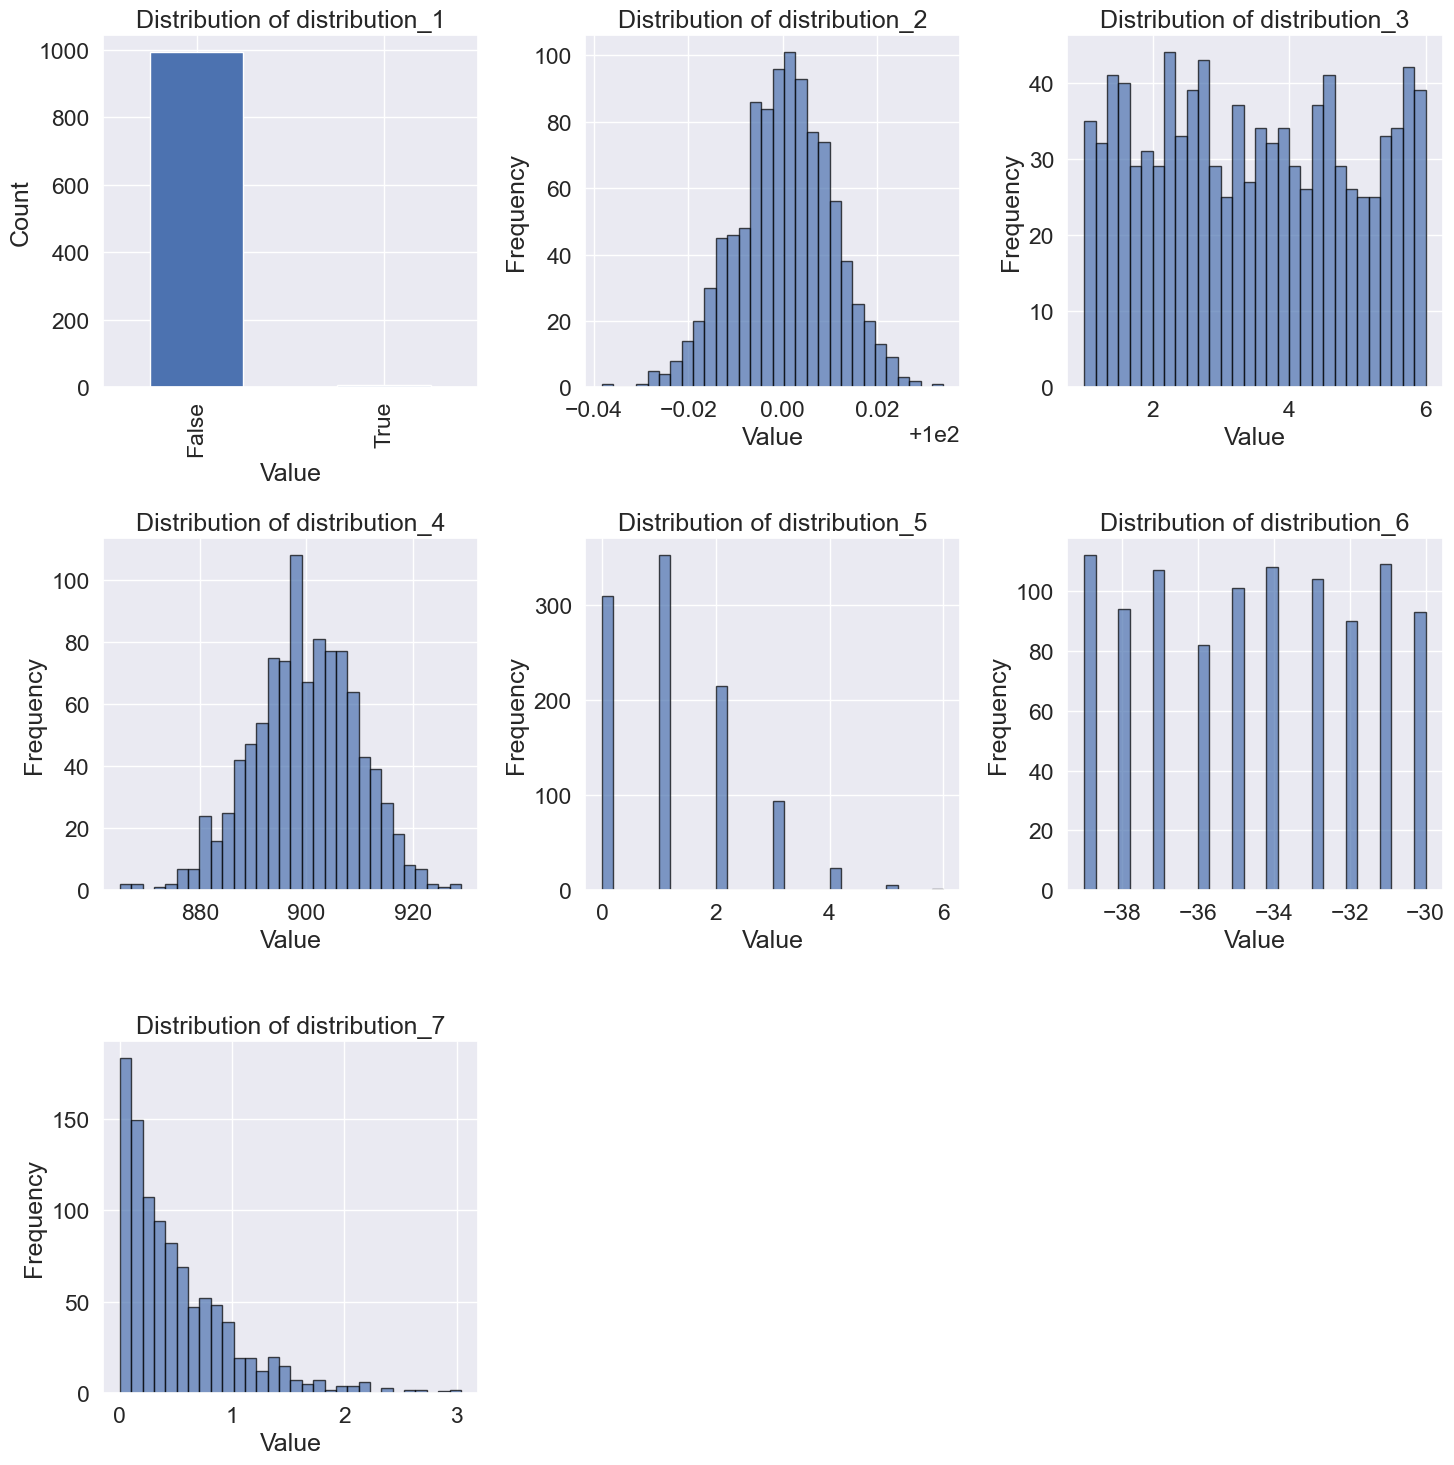

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import math

distributions = pd.read_csv('data/distributions.csv')

num_cols = len(distributions.columns)
rows = math.ceil(num_cols / 3)
cols = 3

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

for i, col_name in enumerate(distributions.columns):
    ax = axes[i]
    if distributions[col_name].dtype == 'bool':
        distributions[col_name].value_counts().plot(kind='bar', ax=ax)
        ax.set_title(f'Distribution of {col_name}')
        ax.set_xlabel('Value')
        ax.set_ylabel('Count')
    else:
        ax.hist(distributions[col_name], bins=30, edgecolor='black', alpha=0.7)
        ax.set_title(f'Distribution of {col_name}')
        ax.set_xlabel('Value')
        ax.set_ylabel('Frequency')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('distributions_plots.png')

3. Each column of the `distributions` dataframe contains data drawn from a different distribution. **Associate each column to its probability distribution.** This is the list of the probability distributions used (one for each column):
    - Bernoulli
    - Binomial
    - Continuous Uniform
    - Gaussian (Normal)
    - Discrete Uniform
    - Poisson
    - Exponential (this was not explain in classroom, go by exclusion)

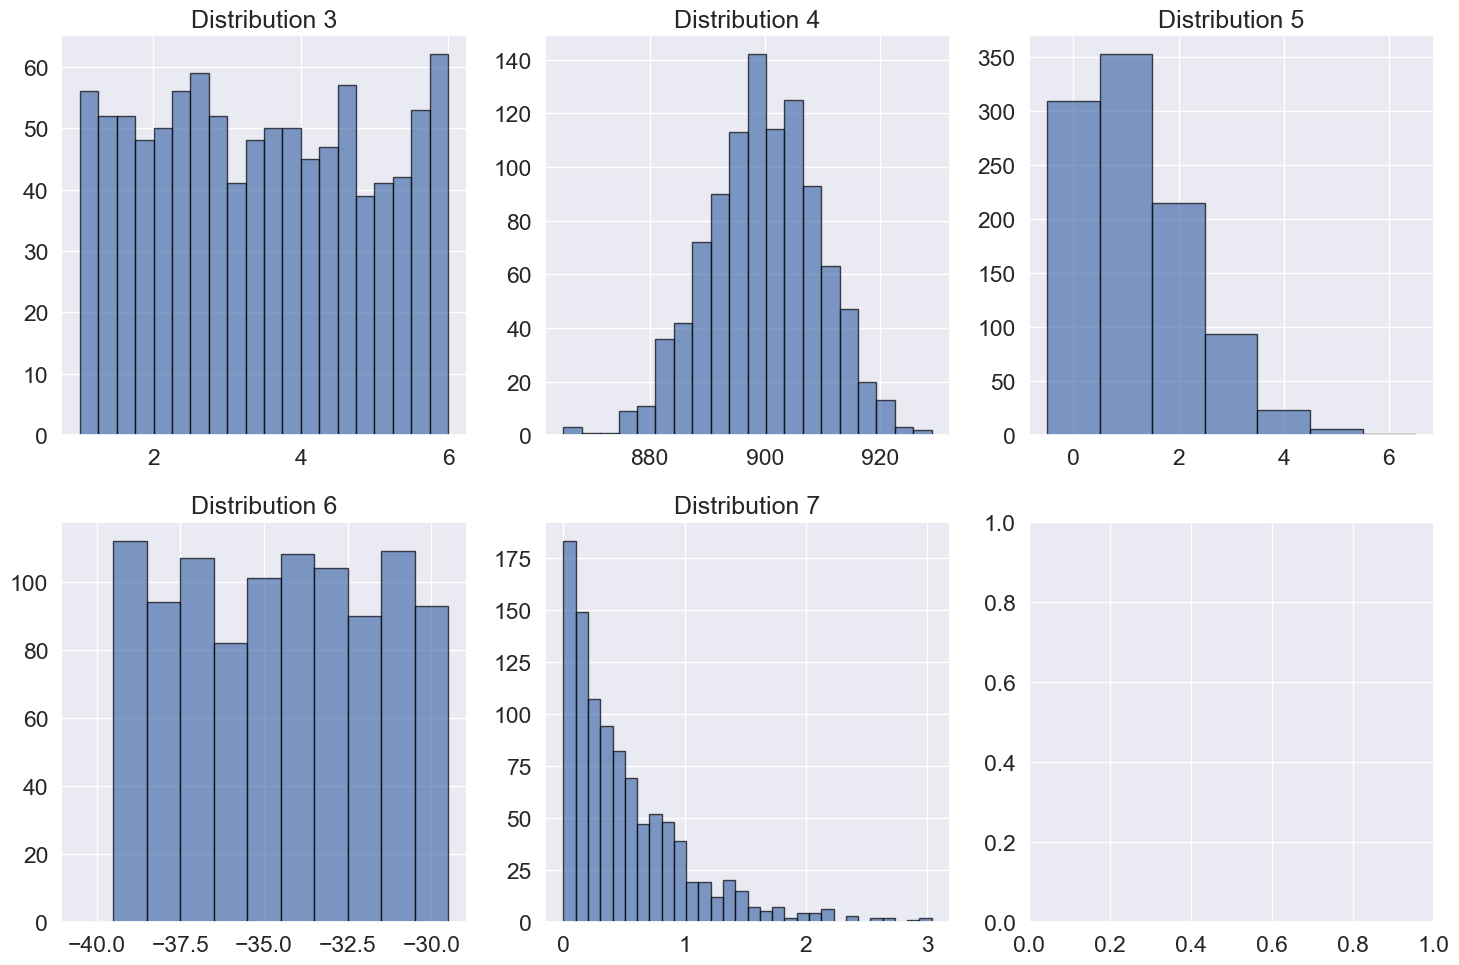

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

distributions = pd.read_csv('data/distributions.csv')

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

# Distribution 3 (Candidate: Continuous Uniform)
axes[0].hist(distributions['distribution_3'], bins=20, edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution 3')

# Distribution 4 (Candidate: Binomial)
axes[1].hist(distributions['distribution_4'], bins=20, edgecolor='black', alpha=0.7)
axes[1].set_title('Distribution 4')

# Distribution 5 (Candidate: Poisson)
axes[2].hist(distributions['distribution_5'], bins=range(8), edgecolor='black', alpha=0.7, align='left')
axes[2].set_title('Distribution 5')

# Distribution 6 (Candidate: Discrete Uniform)
axes[3].hist(distributions['distribution_6'], bins=range(-40, -28), edgecolor='black', alpha=0.7, align='left')
axes[3].set_title('Distribution 6')

# Distribution 7 (Candidate: Exponential)
axes[4].hist(distributions['distribution_7'], bins=30, edgecolor='black', alpha=0.7)
axes[4].set_title('Distribution 7')

plt.tight_layout()
plt.savefig('distribution_shapes.png')